# import thư vien

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from pathlib import Path
from urllib.parse import unquote
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    balanced_accuracy_score,
    roc_curve,
    ConfusionMatrixDisplay,
)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from tensorflow.keras import Model
from tensorflow.keras.layers import Concatenate, Input, Dense, Dropout
import xgboost as xgb

# Cấu hình reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# Đường dẫn dataset (sửa lại cho đúng)
DATA_PATH = Path.cwd().parent / "Dataset" / "capec_small_multilabel2.csv"

# 1. ĐỌC DỮ LIỆU

In [20]:

# ═══════════════════════════════════════════════════════════════════════════════
# 1. ĐỌC DỮ LIỆU
# ═══════════════════════════════════════════════════════════════════════════════
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Dataset shape: {df.shape}")

Dataset shape: (10000, 41)


# 2. TIỀN XỬ LÝ URL 

In [21]:

# ═══════════════════════════════════════════════════════════════════════════════
# 2. TIỀN XỬ LÝ URL NÂNG CAO & TOKENIZATION (CHAR-LEVEL)
# ═══════════════════════════════════════════════════════════════════════════════
def advanced_preprocess_url(url: str) -> str:
    """Chuẩn hóa URL: giải mã, thay số, IP, domain, xóa scheme, tracking"""
    try:
        url = unquote(url)
    except:
        pass
    url = url.lower()
    url = re.sub(r"^[a-z]+://", "", url)
    url = re.sub(r"\b(?:\d{1,3}\.){3}\d{1,3}\b", "<IP>", url)
    url = re.sub(r"\d+", "<NUM>", url)
    url = re.sub(r"([a-z0-9\-]+\.)+[a-z]{2,}", "<DOMAIN>", url)
    url = re.sub(r"utm_[a-z_]+=[^&]*&?", "", url)
    url = re.sub(r"&$", "", url)
    return url


raw_urls = df["request_http_request"].astype(str)
processed_urls = raw_urls.apply(advanced_preprocess_url)

# Tokenizer char-level
MAX_URL_LEN = 400
tokenizer = Tokenizer(char_level=True, filters="", lower=False)
tokenizer.fit_on_texts(processed_urls)
VOCAB_SIZE = len(tokenizer.word_index) + 1
EMBED_DIM = 128

sequences = tokenizer.texts_to_sequences(processed_urls)
X_seq = pad_sequences(
    sequences, maxlen=MAX_URL_LEN, padding="post", truncating="post", value=0
)
print(f"X_seq shape: {X_seq.shape} | Vocab size: {VOCAB_SIZE}")

X_seq shape: (10000, 400) | Vocab size: 70


# 3. TRÍCH XUẤT ĐẶC TRƯNG

In [22]:
# ═══════════════════════════════════════════════════════════════════════════════
# 3. TRÍCH XUẤT ĐẶC TRƯNG TAY (HAND-CRAFTED FEATURES)
# ═══════════════════════════════════════════════════════════════════════════════
def extract_features(df: pd.DataFrame) -> pd.DataFrame:
    """Trích xuất 35+ đặc trưng từ HTTP log"""
    feat = pd.DataFrame(index=df.index)
    url = df["request_http_request"].astype(str).str.lower()
    feat["url_length"] = url.str.len()
    feat["url_depth"] = url.str.count(r"/").clip(0, 20)
    feat["url_has_query"] = url.str.contains(r"\?").astype(int)
    feat["url_query_len"] = url.apply(lambda x: len(x.split("?")[1]) if "?" in x else 0)
    feat["url_special_chars"] = url.str.count(r"[<>'\"%;()&+]")
    feat["url_encoded_chars"] = url.str.count(r"%[0-9a-f]{2}")
    feat["url_double_encoded"] = url.str.count(r"%25[0-9a-f]{2}")
    feat["url_has_dotdot"] = url.str.contains(r"\.\.").astype(int)
    feat["url_has_semicolon"] = url.str.contains(r";").astype(int)
    feat["url_has_union"] = url.str.contains("union").astype(int)
    feat["url_has_select"] = url.str.contains("select").astype(int)
    feat["url_has_exec"] = url.str.contains(r"exec|eval|system|passthru").astype(int)
    feat["url_num_params"] = url.str.count(r"[&=]")

    method = df["request_http_method"].astype(str).str.upper()
    NORMAL_METHODS = {"GET", "POST", "HEAD", "OPTIONS", "PUT", "DELETE", "PATCH"}
    feat["method_is_get"] = (method == "GET").astype(int)
    feat["method_is_post"] = (method == "POST").astype(int)
    feat["method_is_unusual"] = (~method.isin(NORMAL_METHODS)).astype(int)
    feat["has_user_agent"] = df["request_user_agent"].notna().astype(int)
    feat["has_referer"] = df["request_referer"].notna().astype(int)
    feat["has_cookie"] = df["request_cookie"].notna().astype(int)
    feat["has_content_type"] = df["request_content_type"].notna().astype(int)
    feat["has_body"] = df["request_body"].notna().astype(int)

    ua = df["request_user_agent"].fillna("").astype(str).str.lower()
    feat["ua_length"] = ua.str.len()
    feat["ua_has_mozilla"] = ua.str.contains("mozilla").astype(int)
    feat["ua_has_curl_wget"] = ua.str.contains(r"curl|wget|python|nikto|sqlmap").astype(
        int
    )

    feat["status_code"] = pd.to_numeric(
        df["response_http_status_code"], errors="coerce"
    ).fillna(0)
    feat["content_length"] = pd.to_numeric(
        df["response_content_length"], errors="coerce"
    ).fillna(0)
    feat["status_is_4xx"] = (
        (feat["status_code"] >= 400) & (feat["status_code"] < 500)
    ).astype(int)
    feat["status_is_5xx"] = (feat["status_code"] >= 500).astype(int)
    feat["status_is_200"] = (feat["status_code"] == 200).astype(int)
    feat["log_content_length"] = np.log1p(feat["content_length"])

    feat["src_port"] = (
        pd.to_numeric(df["src_port"], errors="coerce").fillna(0).astype(int)
    )
    feat["dst_port"] = (
        pd.to_numeric(df["dst_port"], errors="coerce").fillna(80).astype(int)
    )
    return feat.fillna(0)


X_feat = extract_features(df)
print(f"Feature matrix: {X_feat.shape[0]} × {X_feat.shape[1]}")

# Phân loại cột numeric / binary (để scale numeric)
numeric_cols = [
    "url_length",
    "url_depth",
    "url_query_len",
    "url_special_chars",
    "url_encoded_chars",
    "url_double_encoded",
    "url_num_params",
    "ua_length",
    "src_port",
    "dst_port",
    "log_content_length",
]
binary_cols = [c for c in X_feat.columns if c not in numeric_cols]

Feature matrix: 10000 × 32


# 4. Mã hóa nhãn

In [23]:
# ═══════════════════════════════════════════════════════════════════════════════
# 4. NHÃN BINARY (0 = Normal, 1 = Attack)
# ═══════════════════════════════════════════════════════════════════════════════
y_binary = (df["000 - Normal"] == 0).astype(int).values
print(
    f"Class distribution: Normal = {(y_binary==0).sum()} | Attack = {(y_binary==1).sum()}"
)

Class distribution: Normal = 5000 | Attack = 5000


# 5. Chia tập huấn luyện/validation/ kiểm tra

In [24]:

# ═══════════════════════════════════════════════════════════════════════════════
# 5. TRAIN/VAL/TEST SPLIT 
# ═══════════════════════════════════════════════════════════════════════════════
idx = np.arange(len(X_seq))
idx_tv, idx_test = train_test_split(
    idx, test_size=0.15, random_state=RANDOM_STATE, stratify=y_binary
)
idx_train, idx_val = train_test_split(
    idx_tv, test_size=0.176, random_state=RANDOM_STATE, stratify=y_binary[idx_tv]
)

# URL sequences
X_train_seq = X_seq[idx_train]
X_val_seq = X_seq[idx_val]
X_test_seq = X_seq[idx_test]

y_train = y_binary[idx_train]
y_val = y_binary[idx_val]
y_test = y_binary[idx_test]

# Features tay – cần scale riêng trên train
scaler = StandardScaler()
X_feat_num_train = scaler.fit_transform(X_feat.iloc[idx_train][numeric_cols])
X_feat_num_val = scaler.transform(X_feat.iloc[idx_val][numeric_cols])
X_feat_num_test = scaler.transform(X_feat.iloc[idx_test][numeric_cols])

X_feat_bin_train = X_feat.iloc[idx_train][binary_cols].values
X_feat_bin_val = X_feat.iloc[idx_val][binary_cols].values
X_feat_bin_test = X_feat.iloc[idx_test][binary_cols].values

aux_train = np.hstack([X_feat_num_train, X_feat_bin_train])
aux_val = np.hstack([X_feat_num_val, X_feat_bin_val])
aux_test = np.hstack([X_feat_num_test, X_feat_bin_test])

print(
    f"Train: {X_train_seq.shape[0]}, Val: {X_val_seq.shape[0]}, Test: {X_test_seq.shape[0]}"
)
print(f"Aux features shape: {aux_train.shape[1]}")


Train: 7004, Val: 1496, Test: 1500
Aux features shape: 32


# 6. Dùng xác xuất từ mô hình xgboost làm feature

In [25]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    use_label_encoder=False,
    eval_metric="logloss",
)
xgb_model.fit(aux_train, y_train)

# Dự đoán xác suất
xgb_proba_train = xgb_model.predict_proba(aux_train)[:, 1].reshape(-1, 1)
xgb_proba_val = xgb_model.predict_proba(aux_val)[:, 1].reshape(-1, 1)
xgb_proba_test = xgb_model.predict_proba(aux_test)[:, 1].reshape(-1, 1)

print("\nXGBoost performance on test (using 0.5 threshold):")
xgb_test_pred = (xgb_proba_test.ravel() >= 0.5).astype(int)
print(classification_report(y_test, xgb_test_pred, target_names=["Benign", "Attack"]))



XGBoost performance on test (using 0.5 threshold):
              precision    recall  f1-score   support

      Benign       0.97      0.95      0.96       750
      Attack       0.96      0.97      0.96       750

    accuracy                           0.96      1500
   macro avg       0.96      0.96      0.96      1500
weighted avg       0.96      0.96      0.96      1500



# 7. Xây dựng mô hình 

In [26]:
def build_stacking_lstm():
    url_inp = Input(shape=(MAX_URL_LEN,), name="url")
    x = layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True)(url_inp)
    x = layers.LSTM(128, dropout=0.3, return_sequences=False)(x)  # LSTM
    x = Dropout(0.3)(x)

    prob_inp = Input(shape=(1,), name="xgb_prob")
    y = Dense(8, activation="relu")(prob_inp)

    combined = Concatenate()([x, y])
    z = Dense(64, activation="relu")(combined)
    z = Dropout(0.4)(z)
    out = Dense(1, activation="sigmoid")(z)

    model = Model(inputs=[url_inp, prob_inp], outputs=out)
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")],
    )
    return model

stacking_model = build_stacking_lstm()
stacking_model.summary()

# Callbacks
callbacks_list = [
    callbacks.EarlyStopping(
        monitor="val_auc", mode="max", patience=5, restore_best_weights=True, verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1
    ),
    callbacks.ModelCheckpoint(
        "stacking_best.keras", monitor="val_auc", save_best_only=True, mode="max"
    ),
]

# Huấn luyện stacking model
EPOCHS = 5
BATCH_SIZE = 256
history = stacking_model.fit(
    [X_train_seq, xgb_proba_train],
    y_train,
    validation_data=([X_val_seq, xgb_proba_val], y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks_list,
    verbose=1,
)


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ url (InputLayer)    │ (None, 400)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 400, 128)  │      8,960 │ url[0][0]         │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 400)       │          0 │ url[0][0]         │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 128)       │    131,584 │ embedding_2[0][0… │
│                     │                   │            │ not_equal_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ xgb_prob            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 128)       │          0 │ lstm_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 8)         │         16 │ xgb_prob[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 136)       │          0 │ dropout_4[0][0],  │
│ (Concatenate)       │                   │            │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 64)        │      8,768 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 64)        │          0 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 1)         │         65 │ dropout_5[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 149,393 (583.57 KB)

 Trainable params: 149,393 (583.57 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 112s 4s/step - accuracy: 0.8107 - auc: 0.9117 - loss: 0.5338 - val_accuracy: 0.8336 - val_auc: 0.9367 - val_loss: 0.3983 - learning_rate: 0.0010
Epoch 2/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 51s 2s/step - accuracy: 0.8495 - auc: 0.9495 - loss: 0.3394 - val_accuracy: 0.8790 - val_auc: 0.9857 - val_loss: 0.2731 - learning_rate: 0.0010
Epoch 3/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 80s 2s/step - accuracy: 0.9162 - auc: 0.9817 - loss: 0.2431 - val_accuracy: 0.9305 - val_auc: 0.9906 - val_loss: 0.2006 - learning_rate: 0.0010
Epoch 4/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 50s 2s/step - accuracy: 0.9479 - auc: 0.9912 - loss: 0.1806 - val_accuracy: 0.9525 - val_auc: 0.9927 - val_loss: 0.1485 - learning_rate: 0.0010
Epoch 5/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - accuracy: 0.9546 - auc: 0.9937 - loss: 0.1416 - val_accuracy: 0.9566 - val_auc: 0.9941 - val_loss: 0.1212 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 5.


# 8. Đánh giá trên tập xác thực (validation)

In [27]:
# ═══════════════════════════════════════════════════════════════════════════════
# 8. ĐÁNH GIÁ TRÊN VALIDATION ĐỂ TÌM NGƯỠNG TỐI ƯU
# ═══════════════════════════════════════════════════════════════════════════════
y_val_prob = stacking_model.predict(
    [X_val_seq, xgb_proba_val], batch_size=BATCH_SIZE
).ravel()
fpr, tpr, thresholds = roc_curve(y_val, y_val_prob)
best_thresh = thresholds[np.argmax(tpr - fpr)]
print(f"Optimal threshold (Youden) = {best_thresh:.4f}")


6/6 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step  
Optimal threshold (Youden) = 0.7208


# 9. Đánh giá trên tập kiểm tra (test)

6/6 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step

STACKING MODEL (XGBoost + SimpleRNN) - TEST RESULTS
Accuracy         : 0.9553
Balanced Accuracy: 0.9553
Precision        : 0.9803
Recall           : 0.9293
F1-score         : 0.9541
AUC              : 0.9928

Classification Report:
              precision    recall  f1-score   support

  Benign (0)     0.9328    0.9813    0.9565       750
  Attack (1)     0.9803    0.9293    0.9541       750

    accuracy                         0.9553      1500
   macro avg     0.9566    0.9553    0.9553      1500
weighted avg     0.9566    0.9553    0.9553      1500


Confusion Matrix:
[[736  14]
 [ 53 697]]
TN=736, FP=14, FN=53, TP=697


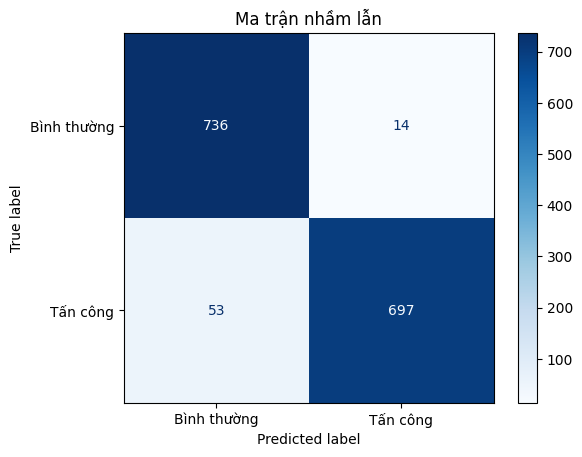

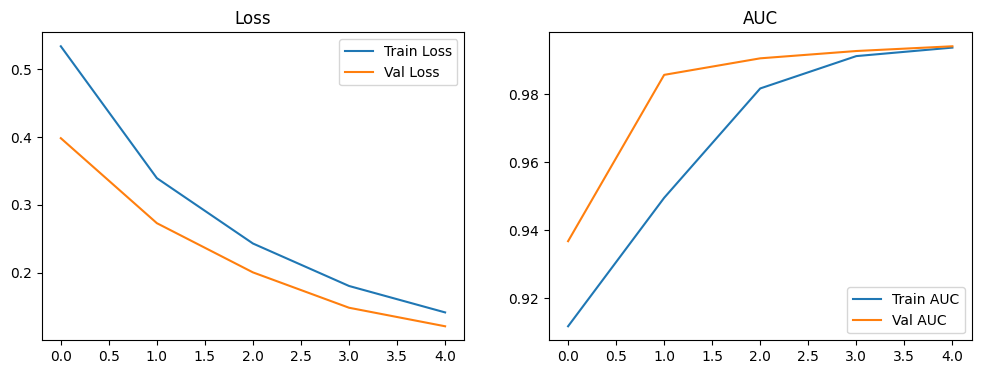

In [28]:

# ═══════════════════════════════════════════════════════════════════════════════
# 9. TEST SET EVALUATION
# ═══════════════════════════════════════════════════════════════════════════════
y_test_prob = stacking_model.predict(
    [X_test_seq, xgb_proba_test], batch_size=BATCH_SIZE
).ravel()
y_test_pred = (y_test_prob >= best_thresh).astype(int)

acc = accuracy_score(y_test, y_test_pred)
bal_acc = balanced_accuracy_score(y_test, y_test_pred)
prec = precision_score(y_test, y_test_pred)
rec = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)
auc = roc_auc_score(y_test, y_test_prob)

print("\n" + "=" * 60)
print("STACKING MODEL (XGBoost + SimpleRNN) - TEST RESULTS")
print("=" * 60)
print(f"Accuracy         : {acc:.4f}")
print(f"Balanced Accuracy: {bal_acc:.4f}")
print(f"Precision        : {prec:.4f}")
print(f"Recall           : {rec:.4f}")
print(f"F1-score         : {f1:.4f}")
print(f"AUC              : {auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test, y_test_pred, target_names=["Benign (0)", "Attack (1)"], digits=4
    )
)

cm = confusion_matrix(y_test, y_test_pred)
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion Matrix:\n{cm}")
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

# Vẽ ma trận nhầm lẫn
plt.rcParams["font.sans-serif"] = [
    "Arial Unicode MS",
    "DejaVu Sans",
    "SimHei",
    "sans-serif",
]
plt.rcParams["axes.unicode_minus"] = False
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["Bình thường", "Tấn công"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Ma trận nhầm lẫn")
plt.show()

# Vẽ đường cong học
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_title("Loss")
axes[0].legend()
axes[1].plot(history.history["auc"], label="Train AUC")
axes[1].plot(history.history["val_auc"], label="Val AUC")
axes[1].set_title("AUC")
axes[1].legend()
plt.show()